# Where feature selectors work and where they break

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/firefly1248/demo-notebooks/blob/main/notebooks/feature_selection/selector_characterization.ipynb)

The companion notebook [standalone_tests_feature_selection](standalone_tests_feature_selection.ipynb)
ran feature selectors on one synthetic pool: 196 columns, 14 useful features (10 additive, 4 that act
only together with a partner) and 182 noise columns. This notebook asks under which properties of the
data each selector keeps the useful features and drops the noise, and under which it fails. It varies
the data in a designed experiment and reports the effect of each factor, instead of ranking the
selectors on a set of datasets.

- **8a.** A full 2^4 factorial design on the pool at interaction strength s = 0.25, 3 seeds per cell: the number of noise
  columns, the number of levels of the categorical noise columns, correlated copies of two useful
  features, and the outcome type.
- **8b.** Relabeling the category codes, which changes no information.
- **8c.** Two public tables, Default of Credit Card Clients and Diabetes 130-US: real columns with an
  injected noise block, and real columns with a synthetic outcome whose true features are known.

The hypotheses H36 to H46 were written before the run. Seeds 7100 to 7102 and the base cell are those
of Part 7b of the companion notebook, so the base cell repeats its numbers, except the shadow cutoff,
which averages 5 new shuffles instead of the first one.

Every run (one cell, one seed) is saved as a JSON file in `RUN_DIR`. An interrupted execution resumes
at the first run without a file, and a second execution only reads the files. A full run takes about
20 hours on an Apple M4 Pro (14 cores). The environment variable `QUICK=1` (on Colab, `%env QUICK=1`
before the first cell) gives a short run with 1 seed and 4,000 rows, whose numbers are not the ones
reported here.

In [1]:
import os
from importlib.metadata import version, PackageNotFoundError

QUICK = os.environ.get("QUICK") == "1"  # on Colab: run %env QUICK=1 before this cell
PINS = {"catboost": "1.2.10", "lightgbm": "4.7.0", "BorutaShap": "1.0.17", "probatus": "3.2.1",
        "scikit-learn": "1.9.1", "shap": "0.54.1"}   # before 1.8, LogisticRegressionCV ignores l1_ratios and fits L2


def installed(package):
    try:
        return version(package)
    except PackageNotFoundError:
        return None


if any(installed(p) != v for p, v in PINS.items()):
    specs = " ".join(f"{p}=={v}" for p, v in PINS.items())
    !pip install -q {specs}

os.environ.setdefault("TQDM_DISABLE", "1")   # BorutaShap's progress bars; tqdm reads this at import
import json
import platform
import subprocess
import time
import warnings
from collections import namedtuple
from contextlib import contextmanager
from itertools import combinations, permutations, product
from pathlib import Path
from types import SimpleNamespace

import catboost
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from catboost import CatBoostClassifier, CatBoostRegressor, Pool
from lightgbm import LGBMClassifier, LGBMRegressor
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.stats import binomtest, false_discovery_control
from sklearn.compose import ColumnTransformer
from sklearn.datasets import fetch_openml
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LassoCV, LogisticRegressionCV
from sklearn.metrics import r2_score, roc_auc_score
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore")
if not hasattr(stats, "binom_test"):   # removed in SciPy 1.12; BorutaShap 1.0.17 imports it and passes counts as floats
    stats.binom_test = lambda x, n=None, p=0.5, alternative="two-sided": binomtest(
        round(x), round(n), p, alternative=alternative).pvalue
if not hasattr(np, "NaN"):             # removed in NumPy 2.0, used by BorutaShap
    np.NaN = np.nan
from BorutaShap import BorutaShap
from probatus.feature_elimination import ShapRFECV

pd.set_option("display.width", 220, "display.max_columns", 40)


def cpu_model():
    if os.path.exists("/proc/cpuinfo"):
        return next((l.split(":", 1)[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name")),
                    platform.processor())
    return subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()


N_JOBS = int(os.environ.get("N_JOBS", -1))  # threads for CatBoost, LightGBM and the forest
RUN_DIR = Path(os.environ.get("RUN_DIR", "selector_characterization_runs" + ("_quick" if QUICK else "")))
RUN_DIR.mkdir(exist_ok=True)
print(f"python {platform.python_version()}, " + ", ".join(
    f"{m.__name__} {m.__version__}" for m in (np, pd, scipy, sklearn, catboost, matplotlib)))
print(", ".join(f"{p} {version(p)}" for p in PINS if p not in ("catboost", "scikit-learn")))
print(f"CPU: {cpu_model()}, {os.cpu_count()} logical cores, N_JOBS = {N_JOBS}, runs saved in {RUN_DIR}")
if QUICK:
    print("QUICK mode: 1 seed, 4,000 rows and short selector settings; numbers are not the published ones")

TIMES = {}


@contextmanager
def timed(block, store=TIMES):
    t = time.perf_counter()
    yield
    store[block] = store.get(block, 0) + time.perf_counter() - t


plt.rcParams.update({"font.size": 15, "axes.titlesize": 16, "axes.labelsize": 15, "xtick.labelsize": 15,
                     "ytick.labelsize": 15, "legend.fontsize": 14, "legend.frameon": False,
                     "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 200})

python 3.12.12, numpy 2.5.3, pandas 3.0.5, scipy 1.18.1, sklearn 1.9.1, catboost 1.2.10, matplotlib 3.11.2
lightgbm 4.7.0, BorutaShap 1.0.17, probatus 3.2.1
CPU: Apple M4 Pro, 14 logical cores, N_JOBS = -1, runs saved in selector_characterization_runs


## The data

The generator is the pool of the companion notebook (Part 4a) with four factors. The cell with 182
noise columns, 4 levels, no copies and a binary outcome is the pool itself, value for value.

| Factor | Level - | Level + |
|---|---|---|
| Noise columns | 50 (41 Gaussian, 9 categorical) | 182 (150 Gaussian, 32 categorical) |
| Levels of each categorical noise column | 4 | 1,000, equally likely |
| Correlated copies | none | 5 copies each of distance_km and u, correlation 0.9 |
| Outcome | binary | regression |

- The 50 noise columns are the first 41 Gaussian and the first 9 categorical columns of the 182, so
  cells of one seed share their columns. Every factor effect is a difference between matched runs.
- The copies of distance_km are built on its log scale: z' = 0.9 z + sqrt(0.19) e, with z the
  standardized log distance. They are not in the logit.
- The regression outcome is the latent variable of the same logistic model: the logit plus logistic
  noise, drawn given the binary outcome, so the binary outcome is exactly the sign of the regression
  outcome. The binary outcome therefore carries less information about the logit, and the best R2 is
  about 0.37.
- The 1,000 levels are equally likely, about 14 training rows per level. The categories of the
  Diabetes table in 8c are skewed instead.

In [2]:
CITY_LEVELS = np.log([300, 600, 900, 1500])
CITY_RELABEL = np.array(min(permutations(range(4)), key=lambda q: abs(np.corrcoef(q, CITY_LEVELS)[0, 1])))
ADD_COEF = 0.4 * np.array([1, -1] * 4)
POOL_INTERCEPT = -1.0
ADD_COLS = [f"add_{i + 1}" for i in range(8)]
PAIR_COLS = ["city", "log_price", "hour", "distance_km", "u", "v"]
USEFUL = ADD_COLS + PAIR_COLS
INTER_ONLY = ["city", "hour", "u", "v"]
AUX_OFFSET, FRESH_OFFSET, CV_SEED = 900, 500, 0

S8 = 0.25
SEEDS8 = range(7100, 7101 if QUICK else 7103)
N8 = 4_000 if QUICK else 20_000
NOISE_LEVELS = {50: (41, 9), 182: (150, 32)}   # noise columns: (Gaussian, categorical)
CARD_LEVELS = (4, 1000)
COPIES, COPY_RHO = 5, 0.9
COPY_COLS = {c: [f"{c}_copy_{k + 1}" for k in range(COPIES)] for c in ("distance_km", "u")}
FACTORS = {"noise": (50, 182), "card": CARD_LEVELS, "copies": (False, True), "outcome": ("binary", "regression")}


def to_z(distance):   # distance_km on its standardized log scale
    return (np.log(distance) - np.log(6)) / 0.6


def from_z(z):
    return np.exp(np.log(6) + 0.6 * z)


def copy_block(base, e):
    # copies correlated COPY_RHO with the standardized column base, one per column of the noise e
    return COPY_RHO * base[:, None] + np.sqrt(1 - COPY_RHO ** 2) * e


def gen_cell(seed, noise=182, card=4, copies=False, outcome="binary", s=S8, n=N8):
    # one 8a dataset; noise=182, card=4, no copies and a binary outcome is the pool of Part 4a
    rng = np.random.default_rng(seed)
    add = rng.normal(size=(n, 8))
    city = rng.integers(0, 4, n)
    log_price = CITY_LEVELS[city] + rng.normal(0, 0.25, n)
    hour = rng.uniform(0, 24, n)
    distance_km = rng.lognormal(mean=np.log(6), sigma=0.6, size=n)
    z = to_z(distance_km)
    night = np.cos(2 * np.pi * hour / 24)
    u, v = rng.normal(size=n), rng.normal(size=n)
    logit = (add @ ADD_COEF + 8 * s * (log_price - CITY_LEVELS[city]) + 0.3 * z + 2.5 * s * night * z
             + 1.5 * s * np.sign(u) * np.sign(v) + POOL_INTERCEPT)
    y = rng.binomial(1, 1 / (1 + np.exp(-logit)))
    gauss = rng.normal(size=(n, 150))
    cat = rng.integers(0, card, (n, 32))   # the last draw of the stream, so the number of levels changes nothing above
    n_gauss, n_cat = NOISE_LEVELS[noise]
    df = pd.DataFrame(add, columns=ADD_COLS).assign(city=CITY_RELABEL[city], log_price=log_price, hour=hour,
                                                      distance_km=distance_km, u=u, v=v)
    df = pd.concat([df, pd.DataFrame(gauss[:, :n_gauss], columns=[f"gnoise_{i + 1}" for i in range(n_gauss)]),
                    pd.DataFrame(cat[:, :n_cat], columns=[f"cnoise_{i + 1}" for i in range(n_cat)])], axis=1)
    if copies:   # own streams for the copies and the regression noise, so each factor changes only its own part
        e = np.random.default_rng((seed + AUX_OFFSET, 0)).normal(size=(n, 2 * COPIES))
        df = pd.concat([df, pd.DataFrame(np.c_[from_z(copy_block(z, e[:, :COPIES])), copy_block(u, e[:, COPIES:])],
                                         columns=COPY_COLS["distance_km"] + COPY_COLS["u"])], axis=1)
    if outcome == "regression":
        # logistic noise drawn given the binary y, so that y_binary = (y > 0)
        f0, w = 1 / (1 + np.exp(logit)), np.random.default_rng((seed + AUX_OFFSET, 6)).uniform(size=n)   # f0 = P(noise <= -logit)
        q = np.where(y == 1, f0 + w * (1 - f0), w * f0)
        y = logit + np.log(q / (1 - q))
    return df, y


Data = namedtuple("Data", "df y Xtr Xte ytr yte fresh fresh_y task cats noise useful inter copies card")


def split(X, y, seed):
    # the 70/30 split of the companion notebook, stratified on the binary outcome (the sign of the regression one)
    return train_test_split(X, y, test_size=0.3, random_state=seed, stratify=(np.asarray(y) > 0).astype(int))


def cell_data(seed, noise, card, copies, outcome):
    df, y = gen_cell(seed, noise, card, copies, outcome)
    fresh, fresh_y = gen_cell(seed + FRESH_OFFSET, noise, card, copies, outcome)
    cats = ["city"] + [c for c in df if c.startswith("cnoise")]
    return Data(df, y, *split(df, y, seed), fresh, fresh_y, outcome, cats,
                [c for c in df if "noise" in c], USEFUL, INTER_ONLY,
                COPY_COLS["distance_km"] + COPY_COLS["u"] if copies else [], card)


d = cell_data(SEEDS8[0], 182, 4, False, "regression")
print(f"seed {SEEDS8[0]}, regression: sign of y equals the binary outcome:",
      bool(((d.y > 0) == (cell_data(SEEDS8[0], 182, 4, False, "binary").y == 1)).all()))
for cfg in product(*FACTORS.values()):
    d = cell_data(SEEDS8[0], *cfg)
    print(dict(zip(FACTORS, cfg)), f"{d.df.shape[1]} columns,",
          f"base rate {d.y.mean():.3f}" if cfg[3] == "binary" else f"y sd {d.y.std():.2f}")

seed 7100, regression: sign of y equals the binary outcome: True


{'noise': 50, 'card': 4, 'copies': False, 'outcome': 'binary'} 64 columns, base rate 0.320
{'noise': 50, 'card': 4, 'copies': False, 'outcome': 'regression'} 64 columns, y sd 2.30
{'noise': 50, 'card': 4, 'copies': True, 'outcome': 'binary'} 74 columns, base rate 0.320


{'noise': 50, 'card': 4, 'copies': True, 'outcome': 'regression'} 74 columns, y sd 2.30
{'noise': 50, 'card': 1000, 'copies': False, 'outcome': 'binary'} 64 columns, base rate 0.320


{'noise': 50, 'card': 1000, 'copies': False, 'outcome': 'regression'} 64 columns, y sd 2.30
{'noise': 50, 'card': 1000, 'copies': True, 'outcome': 'binary'} 74 columns, base rate 0.320
{'noise': 50, 'card': 1000, 'copies': True, 'outcome': 'regression'} 74 columns, y sd 2.30
{'noise': 182, 'card': 4, 'copies': False, 'outcome': 'binary'} 196 columns, base rate 0.320


{'noise': 182, 'card': 4, 'copies': False, 'outcome': 'regression'} 196 columns, y sd 2.30


{'noise': 182, 'card': 4, 'copies': True, 'outcome': 'binary'} 206 columns, base rate 0.320
{'noise': 182, 'card': 4, 'copies': True, 'outcome': 'regression'} 206 columns, y sd 2.30
{'noise': 182, 'card': 1000, 'copies': False, 'outcome': 'binary'} 196 columns, base rate 0.320
{'noise': 182, 'card': 1000, 'copies': False, 'outcome': 'regression'} 196 columns, y sd 2.30


{'noise': 182, 'card': 1000, 'copies': True, 'outcome': 'binary'} 206 columns, base rate 0.320


{'noise': 182, 'card': 1000, 'copies': True, 'outcome': 'regression'} 206 columns, y sd 2.30


## The selectors

Eight rules that return a set of kept columns (nine in the cells with copies), and three scores that
rank the columns. The settings
are those of the companion notebook unless stated.

- **Shadow cutoff (CB LFC):** CatBoost on the columns plus a shuffled copy of each; a column is kept
  if its LossFunctionChange on the holdout beats the largest LFC of any shuffled copy. Here 5 shuffles
  per run: counts are the mean over the shuffles, and the kept set is the columns kept in at least 3.
- **PIMP LFC and PIMP PVC:** the LFC and PredictionValuesChange of CatBoost against their own null
  from 30 refits on a shuffled target; a normal fit of the null gives a one-sided p-value, kept at
  Benjamini-Hochberg q < 0.1.
- **Knockoffs:** derandomized model-X knockoffs. Every column is drawn afresh from the known
  distribution of the cell, W = LFC of the column minus LFC of its knockoff in one fit on both, 10
  draws, knockoff+ at q = 0.1 in each, e-BH at q = 0.1. City and log_price are one group, and a copy
  block (the original column and its 5 copies) is one group drawn jointly.
- **Knockoffs (column):** only in the cells with copies (H46). The two copy blocks get exact
  Gaussian knockoffs per column (equicorrelated, on the z scale), so each column is tested given its
  copies.
- **CPSS:** stability selection with 50 pairs of complementary halves of the training rows, the top 14
  by LFC on the holdout rows of a CatBoost fit on each half, kept at a selection frequency of at least 0.75.
- **BorutaShap:** BorutaShap 1.0.17 with CatBoost, 20 trials, as in Part 6b.
- **ShapRFECV:** probatus 3.2.1 with LightGBM, step 0.2, 3-fold CV, the `best_parsimonious` set. Its
  model is LightGBM, so its effects mix the selector and the model.
- **L1:** L1 logistic regression (Lasso for the regression outcome), the penalty chosen by 5-fold CV: 10
  values of C by ROC AUC for the binary outcome, the 100 penalties of LassoCV by squared error for the
  regression outcome; numeric
  columns standardized, categorical columns one-hot encoded (sparse) and scaled. A column is kept if
  any of its coefficients is nonzero.
- **Pair scan** (score): the G test of x_i independent of y given x_j for every pair, 8 quantile bins
  for numeric columns (and for the regression outcome), categorical codes as they are; the score is
  -log of the smallest p-value over the partners.
- **RF impurity** (score): the impurity importance of a random forest (300 trees, `max_features`
  sqrt, leaf 20) that reads category codes as numbers.
- **CB LFC** (score): the LFC of one CatBoost fit, the ranking of the shadow cutoff.

Refit quality: CatBoost refit on the kept columns, scored on a fresh draw (ROC AUC for the binary
outcome, R2 for the regression one), minus the same refit on the 14 useful features.

In [3]:
PIMP_RUNS = 5 if QUICK else 30
KO_DRAWS = 3 if QUICK else 10
CPSS_PAIRS = 5 if QUICK else 50
SHADOW_SHUFFLES = 2 if QUICK else 5
BORUTA_TRIALS = 3 if QUICK else 20
Q8, CPSS_TOP, CPSS_PI, SCAN_BINS, TOP = 0.1, 14, 0.75, 8, 14
CB_PARAMS = dict(iterations=300, depth=6, learning_rate=0.1, random_seed=0, verbose=0, thread_count=N_JOBS,
                 allow_writing_files=False)
LGB_PARAMS = dict(n_estimators=300, learning_rate=0.1, num_leaves=63, min_child_samples=20, n_jobs=N_JOBS, verbose=-1)


def binary(d):
    return d.task == "binary"


def fit_cb(d, X, y, **kw):
    cats = [c for c in d.cats if c in X]
    model = (CatBoostClassifier if binary(d) else CatBoostRegressor)(cat_features=cats, **{**CB_PARAMS, **kw})
    return model.fit(X, y)


def lfc(d, model, X, y):
    pool = Pool(X, y, cat_features=[c for c in d.cats if c in X])
    return pd.Series(model.get_feature_importance(pool, type="LossFunctionChange"), index=X.columns)


def refit_score(d, cols):
    # CatBoost refit on cols, scored on the fresh draw: ROC AUC or R2
    m = fit_cb(d, d.Xtr[cols], d.ytr)
    if binary(d):
        return roc_auc_score(d.fresh_y, m.predict_proba(d.fresh[cols])[:, 1])
    return r2_score(d.fresh_y, m.predict(d.fresh[cols]))


def aug_lfc(d, aug, prefix):
    # CatBoost on the columns plus their prefixed doubles (same index as d.df); LFC of every column on the test rows
    dd = d._replace(cats=d.cats + [prefix + c for c in d.cats])
    return lfc(dd, fit_cb(dd, aug.loc[d.Xtr.index], d.ytr), aug.loc[d.Xte.index], d.yte)


def shadow_cut(d, seed, k):
    # shuffle k of every column; a column is kept if its LFC beats the largest LFC of any shuffled copy
    rng = np.random.default_rng((seed + AUX_OFFSET, 4, k))
    shadow =d.df.apply(lambda col: rng.permutation(col.to_numpy())).add_prefix("shadow_")
    v = aug_lfc(d, pd.concat([d.df, shadow], axis=1), "shadow_")
    return v[d.df.columns] > v[shadow.columns].max()


def pimp(d, seed):
    # PVC and LFC against their own nulls from PIMP_RUNS refits on shuffled targets; kept at BH q < Q8
    def scores(ytr, yte):
        cb = fit_cb(d, d.Xtr, ytr)
        return pd.DataFrame({"PVC": cb.get_feature_importance(), "LFC": lfc(d, cb, d.Xte, yte)})
    rng = np.random.default_rng((seed + AUX_OFFSET, 1))
    real = scores(d.ytr, d.yte)
    null = [scores(rng.permutation(d.ytr), rng.permutation(d.yte)) for _ in range(PIMP_RUNS)]
    kept = {}
    for m in real:
        N = pd.concat([n[m] for n in null], axis=1)
        sd = N.std(axis=1, ddof=1)
        p = np.where(sd > 0, stats.norm.sf((real[m] - N.mean(axis=1)) / sd), 1.0)   # never used in the null fits: not kept
        kept[f"PIMP {m}"] = pd.Series(false_discovery_control(p) < Q8, index=real.index)
    return kept


def cpss(d, seed):
    # share of 2 x CPSS_PAIRS fits on complementary halves of the training rows with the column in the LFC top CPSS_TOP
    rng = np.random.default_rng((seed + AUX_OFFSET, 2))
    freq = pd.Series(0.0, index=d.Xtr.columns)
    for _ in range(CPSS_PAIRS):
        for half in np.array_split(rng.permutation(len(d.Xtr)), 2):
            cb = fit_cb(d, d.Xtr.iloc[half], d.ytr[half])
            freq[lfc(d, cb, d.Xte, d.yte).nlargest(CPSS_TOP).index] += 1
    return freq / (2 * CPSS_PAIRS)


def boruta(d, seed):
    X = d.df.astype({c: str for c in d.cats}).astype({c: "category" for c in d.cats})
    model = (CatBoostClassifier if binary(d) else CatBoostRegressor)(**CB_PARAMS)
    bs = BorutaShap(model=model, importance_measure="shap", classification=binary(d), percentile=100, pvalue=0.05)
    bs.fit(X, d.y, n_trials=BORUTA_TRIALS, random_state=seed, train_or_test="test", normalize=True, verbose=False,
           stratify=d.y if binary(d) else None)
    return pd.Series(d.df.columns.isin(bs.accepted), index=d.df.columns)


def lgb_frame(d, X):
    # LightGBM reads the categorical columns as categories
    return X.astype({c: pd.CategoricalDtype(np.sort(d.df[c].unique())) for c in d.cats if c in X})


def shap_rfecv(d, seed):
    model = (LGBMClassifier if binary(d) else LGBMRegressor)(random_state=seed, **LGB_PARAMS)
    sh = ShapRFECV(model, step=0.2, cv=3, scoring="roc_auc" if binary(d) else "r2", n_jobs=1, random_state=seed)
    sh.fit_compute(lgb_frame(d, d.Xtr), d.ytr, check_additivity=False, feature_perturbation="tree_path_dependent")
    return pd.Series(d.Xtr.columns.isin(sh.get_reduced_features_set(num_features="best_parsimonious")), index=d.Xtr.columns)


def l1_fit(d, seed):
    # |coefficient| of L1 logistic regression (Lasso for regression) with the penalty chosen by CV; a column takes the
    # largest |coefficient| over its one-hot outputs. Returns the scores and the number of levels per categorical column
    num, cat = [c for c in d.Xtr if c not in d.cats], [c for c in d.Xtr if c in d.cats]
    ct = ColumnTransformer([("num", StandardScaler(), num),
                            ("cat", make_pipeline(OneHotEncoder(handle_unknown="ignore"), StandardScaler(with_mean=False)), cat)],
                           sparse_threshold=1.0)
    Z = ct.fit_transform(d.Xtr)
    groups = num + [c for c, lv in zip(cat, ct.named_transformers_["cat"][0].categories_) for _ in lv]
    if binary(d):
        m = LogisticRegressionCV(Cs=10, cv=StratifiedKFold(5, shuffle=True, random_state=CV_SEED), l1_ratios=(1.0,),
                                 solver="liblinear", scoring="roc_auc", n_jobs=N_JOBS, random_state=seed).fit(Z, d.ytr)
    else:
        m = LassoCV(cv=KFold(5, shuffle=True, random_state=CV_SEED), n_jobs=N_JOBS, random_state=seed).fit(Z, d.ytr)
    return pd.Series(np.abs(np.ravel(m.coef_)), index=groups).groupby(level=0).max().reindex(d.Xtr.columns)


def quantile_bins(x):
    return np.searchsorted(np.quantile(x, np.linspace(0, 1, SCAN_BINS + 1)[1:-1]), x, side="right")


def bin_codes(d, X):
    # integer codes per column: categorical columns as they are, numeric columns in SCAN_BINS quantile bins
    return np.column_stack([X[c].to_numpy() if c in d.cats else quantile_bins(X[c]) for c in X.columns]).astype(np.int64)


def g_stat(N):
    # G statistic of x independent of y given z, from the counts N[x, z, y]
    expected = N.sum(axis=2, keepdims=True) * N.sum(axis=0, keepdims=True) / N.sum(axis=(0, 2), keepdims=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        return 2 * np.nansum(N * np.log(N / expected))


def pair_scan(d):
    # score = -log of the smallest p-value over partners j of the G test of x_i independent of y given x_j
    B, cols = bin_codes(d, d.Xtr), d.Xtr.columns
    y = np.asarray(d.ytr) if binary(d) else quantile_bins(d.ytr)
    L, Ly = B.max(axis=0) + 1, int(y.max()) + 1
    score = np.full(len(cols), -np.inf)
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            N = np.bincount((B[:, i] * L[j] + B[:, j]) * Ly + y, minlength=L[i] * L[j] * Ly).reshape(L[i], L[j], Ly)
            for a, b, M in ((i, j, N), (j, i, N.transpose(1, 0, 2))):
                score[a] = max(score[a], -stats.chi2.logsf(g_stat(M), (L[a] - 1) * L[b] * (Ly - 1)))
    return pd.Series(score, index=cols)


def rf_impurity(d, seed):
    rf = (RandomForestClassifier if binary(d) else RandomForestRegressor)(
        n_estimators=300, min_samples_leaf=20, max_features="sqrt", n_jobs=N_JOBS, random_state=seed)
    return pd.Series(rf.fit(d.Xtr, d.ytr).feature_importances_, index=d.Xtr.columns)

Knockoffs need a fresh draw of every column from the distribution of its cell. The copy blocks are
drawn either jointly (a group, the default) or per column. Per column, the block of a standardized
column and its 5 copies is Gaussian with correlation matrix Sigma (0.9 to the original, 0.81 between
copies). The equicorrelated knockoff uses s = 0.07, twice the smallest eigenvalue of Sigma,
so each knockoff correlates about 0.93 with its column.

In [4]:
BLOCK_SIGMA = np.full((COPIES + 1, COPIES + 1), COPY_RHO ** 2)
BLOCK_SIGMA[0, 1:] = BLOCK_SIGMA[1:, 0] = COPY_RHO
np.fill_diagonal(BLOCK_SIGMA, 1.0)
BLOCK_S = min(1.0, 2 * np.linalg.eigvalsh(BLOCK_SIGMA).min())
_A = np.eye(COPIES + 1) - BLOCK_S * np.linalg.inv(BLOCK_SIGMA)          # knockoff mean = Z @ _A.T
_w, _V = np.linalg.eigh(2 * BLOCK_S * np.eye(COPIES + 1) - BLOCK_S ** 2 * np.linalg.inv(BLOCK_SIGMA))
BLOCK_ROOT = _V * np.sqrt(np.clip(_w, 0, None))                          # knockoff noise = e @ BLOCK_ROOT.T


def knockoff_frame(d, rng, per_column=False):
    # every column of the cell drawn afresh (the order of draws of the base cell is that of Part 7b)
    n = len(d.df)
    city = rng.integers(0, 4, n)
    f = {**{c: rng.normal(size=n) for c in ADD_COLS}, "city": CITY_RELABEL[city],
         "log_price": CITY_LEVELS[city] + rng.normal(0, 0.25, n), "hour": rng.uniform(0, 24, n),
         "distance_km": rng.lognormal(np.log(6), 0.6, n), "u": rng.normal(size=n), "v": rng.normal(size=n),
         **{c: rng.normal(size=n) for c in d.noise if c.startswith("gnoise")},
         **{c: rng.integers(0, d.card, n) for c in d.noise if c.startswith("cnoise")}}
    if d.copies:
        for col in COPY_COLS:
            cols, scale = [col] + COPY_COLS[col], to_z if col == "distance_km" else np.asarray
            if per_column:
                block = scale(d.df[cols].to_numpy())
                ko = block @ _A.T + rng.normal(size=block.shape) @ BLOCK_ROOT.T
            else:
                base = scale(f[col])
                ko = np.c_[base, copy_block(base, rng.normal(size=(n, COPIES)))]
            f |= dict(zip(cols, (from_z(ko) if col == "distance_km" else ko).T))
    return pd.DataFrame(f)[d.df.columns]


def ko_group(d, per_column):
    # knockoff groups: city with log_price, and each copy block unless tested per column
    g = {"city": "city, log_price", "log_price": "city, log_price"}
    if d.copies and not per_column:
        g |= {c: f"{col} block" for col in COPY_COLS for c in [col] + COPY_COLS[col]}
    return g


def knockoff_w(d, seed, k, per_column=False):
    # W per group: LFC of the real columns minus LFC of their knockoffs (draw k), CatBoost fit on both
    rng = np.random.default_rng((seed + AUX_OFFSET, 3 + 10 * per_column, k))
    ko = knockoff_frame(d, rng, per_column).add_prefix("ko_")
    aug = pd.concat([d.df, ko], axis=1)
    aug = aug[rng.permutation(aug.columns)]   # CatBoost is not symmetric in column order: mix real columns and knockoffs
    v = aug_lfc(d, aug, "ko_")
    w = pd.Series(v[d.df.columns].to_numpy() - v["ko_" + d.df.columns].to_numpy(), index=d.df.columns)
    g = ko_group(d, per_column)
    return w.groupby(lambda c: g.get(c, c)).sum()


def knockoff_threshold(w, q):
    # knockoff+: the smallest t > 0 with (1 + #{W <= -t}) / #{W >= t} <= q; infinite if there is none
    return next((t for t in np.sort(np.abs(w[w != 0])) if (1 + (w <= -t).sum()) / max(1, (w >= t).sum()) <= q), np.inf)


def derandomized(W, q):
    # e-values averaged over the draws (knockoff+ at level q in each), then e-BH at level q
    p = len(W[0])
    e = sum(p * (w >= (t := knockoff_threshold(w, q))) / (1 + (w <= -t).sum()) for w in W) / len(W)
    top = np.sort(e.to_numpy())[::-1]
    k = max((k for k in range(1, p + 1) if top[k - 1] >= p / (q * k)), default=0)
    return e >= (top[k - 1] if k else np.inf)


def knockoffs(d, seed, per_column=False):
    kept_groups = derandomized([knockoff_w(d, seed, k, per_column) for k in range(KO_DRAWS)], Q8)
    g = ko_group(d, per_column)
    return pd.Series([bool(kept_groups[g.get(c, c)]) for c in d.df.columns], index=d.df.columns), kept_groups


print(f"copy block: s = {BLOCK_S:.3f}, correlation of a column with its knockoff {1 - BLOCK_S:.3f}")

copy block: s = 0.073, correlation of a column with its knockoff 0.927


## 8a: the factorial design

One run is one cell and one seed: every selector on the same data. The responses per rule: useful
features kept (of 14), interaction-only features kept (city, hour, u, v), noise columns kept, copies
kept, distance_km and u kept, and the refit gap. Per score: the same counts in its top 14, and for RF
impurity the median rank of the categorical noise columns among the noise columns (0 = top, 1 =
bottom). The seconds printed per selector are medians on a shared machine, so only their order of
magnitude counts; PIMP LFC and PIMP PVC share their fits.

In [5]:
def cat_noise(d):
    return [c for c in d.noise if c in d.cats]


def counts(d, kept):
    kept = set(kept)
    return dict(useful=len(kept & set(d.useful)), inter=len(kept & set(d.inter)), noise_kept=len(kept & set(d.noise)),
                copies_kept=len(kept & set(d.copies)), dist_u=len(kept & {"distance_km", "u"}))


def run_rules(d, seed, with_knockoffs=False, with_shap=True, ref=None):
    # every rule on one dataset; returns rows with the kept columns, the counts, the refit gap (to the refit on ref,
    # by default the useful features) and the seconds
    rows, kept, T = [], {}, {}
    with timed("Shadow cutoff", T):
        shadow = pd.concat([shadow_cut(d, seed, k) for k in range(SHADOW_SHUFFLES)], axis=1)
    with timed("PIMP", T):
        kept |= pimp(d, seed)
    T["PIMP LFC"] = T["PIMP PVC"] = T.pop("PIMP")
    info = {}
    for name, per_column in (("Knockoffs", False), ("Knockoffs (column)", True)):
        if with_knockoffs and (d.copies or not per_column):
            with timed(name, T):
                kept[name], groups = knockoffs(d, seed, per_column)
            info[name] = dict(groups_kept=int(groups.sum()), noise_groups_kept=int(groups[groups.index.isin(d.noise)].sum()))
    with timed("CPSS", T):
        freq = cpss(d, seed)
    kept["CPSS"] = freq >= CPSS_PI
    info["CPSS"] = {f"freq_{c}": round(float(freq[c]), 3) for c in d.inter + ["distance_km"] if c in freq}
    with timed("BorutaShap", T):
        kept["BorutaShap"] = boruta(d, seed)
    if with_shap:
        with timed("ShapRFECV", T):
            kept["ShapRFECV"] = shap_rfecv(d, seed)
    with timed("L1", T):
        l1 = l1_fit(d, seed)
    kept["L1"] = l1 > 0
    info["L1"] = dict(cat_noise_nonzero=int((l1[cat_noise(d)] > 0).sum()))
    kept["Shadow cutoff"] = shadow.sum(axis=1) >= (SHADOW_SHUFFLES + 1) // 2
    base = refit_score(d, ref or d.useful)
    for rule, k in kept.items():
        cols = list(k.index[k])
        c = counts(d, cols)
        if rule == "Shadow cutoff":   # counts: mean over the shuffles
            c = {key: float(np.mean([counts(d, shadow.index[shadow[j]])[key] for j in shadow])) for key in c}
        rows.append(dict(selector=rule, kept=cols, **c, gap=(refit_score(d, cols) - base) if cols else np.nan,
                         seconds=T[rule], **info.get(rule, {})))
    return rows, base


def run_scores(d, seed):
    # the three rankings; counts in the top 14 and ranks of the interaction-only features
    rows, T, S = [], {}, {}
    with timed("Pair scan", T):
        S["Pair scan"] = pair_scan(d)
    with timed("RF impurity", T):
        S["RF impurity"] = rf_impurity(d, seed)
    with timed("CB LFC", T):
        S["CB LFC"] = lfc(d, fit_cb(d, d.Xtr, d.ytr), d.Xte, d.yte)
    cn = cat_noise(d)
    for m, v in S.items():
        r = v.rank(ascending=False, method="max")
        top = list(r.index[r <= TOP])
        noise_rank = v[d.noise].rank(ascending=False, method="average")
        rows.append(dict(selector=m, kept=top, **counts(d, top), cat_noise_top=int((r[cn] <= TOP).sum()),
                         cat_noise_rank=float(((noise_rank[cn] - 1) / (len(d.noise) - 1)).median()),
                         ranks=r.astype(int).to_dict(), seconds=T[m]))
    return rows


def cached(name, fn, *args):
    # rows of fn(*args), from RUN_DIR if it ran before
    path = RUN_DIR / f"{name}.json"
    if path.exists():
        return json.loads(path.read_text())
    t = time.perf_counter()
    rows = fn(*args)
    print(f"  {name}: {time.perf_counter() - t:.0f} s", flush=True)
    path.write_text(json.dumps(rows, default=float))
    return rows


def run8a(cfg, seed):
    d = cell_data(seed, *cfg)
    rules, base = run_rules(d, seed, with_knockoffs=True)
    return [dict(**dict(zip(FACTORS, cfg)), seed=seed, base=base, p=d.df.shape[1], **r) for r in rules + run_scores(d, seed)]


with timed("Part 8a"):
    R8A = pd.DataFrame([r for seed in SEEDS8 for cfg in product(*FACTORS.values())
                        for r in cached(f"8a_{'_'.join(map(str, cfg))}_{seed}", run8a, cfg, seed)])
print(R8A.groupby("selector").seconds.median().round(0).to_string())

  8a_50_4_False_binary_7100: 743 s


  8a_50_4_False_regression_7100: 536 s


  8a_50_4_True_binary_7100: 709 s


  8a_50_4_True_regression_7100: 596 s


  8a_50_1000_False_binary_7100: 680 s


  8a_50_1000_False_regression_7100: 662 s


... (39 outputs left out)

  8a_182_1000_False_regression_7102: 1273 s


  8a_182_1000_True_binary_7102: 1728 s


  8a_182_1000_True_regression_7102: 2400 s


selector
BorutaShap            114.0
CB LFC                  4.0
CPSS                  326.0
Knockoffs              74.0
Knockoffs (column)     78.0
L1                      8.0
PIMP LFC              146.0
PIMP PVC              146.0
Pair scan               3.0
RF impurity             1.0
Shadow cutoff          37.0
ShapRFECV             328.0


The base cell repeats Part 7b of the companion notebook: the same data, split and random streams. The
shadow cutoff averages 5 new shuffles, and knockoffs use the first 10 of the 20 draws of 7b.

In [6]:
base8 = R8A[(R8A.noise == 182) & (R8A.card == 4) & ~R8A.copies & (R8A.outcome == "binary")]
print("Base cell, per seed: useful / interaction-only / noise kept, refit gap")
print(base8.assign(v=lambda t: t.useful.round(1).astype(str) + " / " + t.inter.round(1).astype(str) + " / "
                   + t.noise_kept.round(1).astype(str) + ", " + t.gap.map(lambda g: f"{g:.3f}" if g == g else "-"))
      .pivot(index="selector", columns="seed", values="v").to_string())

Base cell, per seed: useful / interaction-only / noise kept, refit gap
seed                                 7100                        7101                        7102
selector                                                                                         
BorutaShap        14.0 / 4.0 / 0.0, 0.000    12.0 / 2.0 / 2.0, -0.013    14.0 / 4.0 / 1.0, -0.003
CB LFC                14.0 / 4.0 / 0.0, -         14.0 / 4.0 / 0.0, -         14.0 / 4.0 / 0.0, -
CPSS              14.0 / 4.0 / 0.0, 0.000     14.0 / 4.0 / 0.0, 0.000     14.0 / 4.0 / 0.0, 0.000
Knockoffs         14.0 / 4.0 / 0.0, 0.000     14.0 / 4.0 / 0.0, 0.000     14.0 / 4.0 / 0.0, 0.000
L1             13.0 / 3.0 / 128.0, -0.030  12.0 / 2.0 / 140.0, -0.041  12.0 / 2.0 / 128.0, -0.040
PIMP LFC          14.0 / 4.0 / 0.0, 0.000    14.0 / 4.0 / 1.0, -0.000     14.0 / 4.0 / 0.0, 0.000
PIMP PVC          14.0 / 4.0 / 0.0, 0.000    12.0 / 2.0 / 0.0, -0.012    12.0 / 2.0 / 0.0, -0.012
Pair scan             14.0 / 4.0 / 0.0, -      

### Effects of the factors

A main effect is the mean, over the 24 matched pairs (same seed, the other factors fixed), of the
response at level + minus level -. A two-factor interaction is half the difference between the main
effect of one factor at the + and at the - level of the other. Seeds are shared across cells, so the
3 seeds are the independent units: the tables show the mean and, in brackets, the effect per seed.
The refit gap is on two scales (ROC AUC and R2), so its effects are computed within each outcome, over
12 pairs.

In [7]:
TERMS = list(FACTORS) + [f"{a} x {b}" for a, b in combinations(FACTORS, 2)]


def effects(rows, response, terms=TERMS):
    # main effects and two-factor interactions per selector: (mean, [per seed]). An effect is the mean at level +
    # minus the mean at level - (the second level of each factor is +), so a missing gap drops out of its own level only
    out = {}
    for sel, g in rows.groupby("selector"):
        if g[response].isna().all():
            continue
        sign = {f: np.where(g[f] == FACTORS[f][1], 1, -1) for f in FACTORS}
        for term in terms:
            m = g.assign(x=np.prod([sign[f] for f in term.split(" x ")], axis=0)).groupby(["seed", "x"])[response].mean().unstack()
            per_seed = (m[1] - m[-1]).tolist()
            out[(sel, term)] = (float(np.mean(per_seed)), per_seed)
    return out


def effects_table(rows, response, terms=TERMS):
    e = effects(rows, response, terms)
    sels = [s for s in rows.selector.unique() if (s, terms[0]) in e]
    return pd.DataFrame({t: [f"{e[(s, t)][0]:+.2f} [" + ", ".join(f"{x:+.1f}" for x in e[(s, t)][1]) + "]"
                             for s in sels] for t in terms}, index=sels)


RULES = ["Shadow cutoff", "PIMP LFC", "PIMP PVC", "Knockoffs", "CPSS", "BorutaShap", "ShapRFECV", "L1"]
r8 = R8A[R8A.selector.isin(RULES)]
with pd.option_context("display.max_colwidth", 40):
    for resp, label in (("noise_kept", "noise columns kept"), ("inter", "interaction-only features kept"),
                        ("useful", "useful features kept"), ("copies_kept", "copies kept")):
        print(f"\nMain effects on {label}: mean [per seed]")
        print(effects_table(r8, resp, list(FACTORS)).to_string())
    for o in FACTORS["outcome"]:   # AUC and R2 gaps are not on one scale: effects within each outcome
        print(f"\nMain effects on the refit gap ({'ROC AUC' if o == 'binary' else 'R2'}), {o} outcome")
        print(effects_table(r8[r8.outcome == o], "gap", list(FACTORS)[:3]).to_string())
    print("\nTwo-factor interactions on noise kept")
    print(effects_table(r8, "noise_kept", TERMS[4:]).to_string())
    print("\nTwo-factor interactions on interaction-only features kept")
    print(effects_table(r8, "inter", TERMS[4:]).to_string())


Main effects on noise columns kept: mean [per seed]
                                      noise                          card                    copies                      outcome
PIMP PVC           +0.12 [+0.1, +0.2, +0.0]      -0.04 [-0.1, +0.0, +0.0]  +0.04 [+0.1, +0.0, +0.0]     -0.12 [-0.1, -0.2, +0.0]
PIMP LFC           -0.25 [-0.4, +0.1, -0.5]      -1.00 [-1.4, -0.9, -0.8]  +1.00 [+1.1, +0.9, +1.0]     +0.25 [-0.1, +0.1, +0.8]
Knockoffs          +0.00 [+0.0, +0.0, +0.0]      +0.00 [+0.0, +0.0, +0.0]  +0.00 [+0.0, +0.0, +0.0]     +0.00 [+0.0, +0.0, +0.0]
CPSS               +0.00 [+0.0, +0.0, +0.0]      +0.00 [+0.0, +0.0, +0.0]  +0.00 [+0.0, +0.0, +0.0]     +0.00 [+0.0, +0.0, +0.0]
BorutaShap         +0.54 [+0.5, +0.4, +0.8]      -0.04 [+0.0, -0.1, +0.0]  -0.38 [-0.5, -0.4, -0.2]     +0.46 [+0.5, -0.4, +1.2]
ShapRFECV          +6.33 [+5.6, +6.9, +6.5]     +9.58 [+9.1, +11.1, +8.5]  -1.75 [-1.6, -1.4, -2.2]  -10.92 [-9.9, -11.4, -11.5]
L1             +42.00 [+42.0, +44.0, +40.0] 

                           noise x card            noise x copies           noise x outcome             card x copies            card x outcome          copies x outcome
PIMP PVC       -0.12 [+0.0, -0.2, -0.1]  +0.12 [+0.0, +0.2, +0.1]  -0.04 [+0.0, +0.0, -0.1]  +0.12 [+0.0, +0.0, +0.4]  -0.21 [+0.0, -0.2, -0.4]  -0.46 [+0.0, -0.8, -0.6]
PIMP LFC       +0.00 [+0.0, +0.0, +0.0]  +0.00 [+0.0, +0.0, +0.0]  +0.00 [+0.0, +0.0, +0.0]  +0.00 [+0.0, +0.0, +0.0]  +0.00 [+0.0, +0.0, +0.0]  +0.00 [+0.0, +0.0, +0.0]
Knockoffs      +0.00 [+0.0, +0.0, +0.0]  +0.00 [+0.0, +0.0, +0.0]  +0.00 [+0.0, +0.0, +0.0]  +0.00 [+0.0, +0.0, +0.0]  +0.00 [+0.0, +0.0, +0.0]  +0.00 [+0.0, +0.0, +0.0]
CPSS           +0.21 [+0.2, +0.2, +0.1]  -0.21 [-0.2, -0.2, -0.1]  +0.04 [+0.0, +0.0, +0.1]  +0.21 [+0.2, +0.2, +0.1]  -0.04 [+0.0, +0.0, -0.1]  +0.04 [+0.0, +0.0, +0.1]
BorutaShap     -0.17 [-0.5, +0.0, +0.0]  +0.33 [+0.5, +0.5, +0.0]  +0.17 [+0.0, +0.5, +0.0]  +0.17 [+0.5, +0.0, +0.0]  +0.00 [+0.0, +0.0, +0.0]  -0.17

Figure 1: the main effects and three two-factor interactions on noise columns kept (left), and the main
effects on interaction-only features kept (right), mean of the 3 seeds. Orange: the rule keeps more at
the first level named under the column (182 noise columns, 1,000 levels, copies, regression), blue:
fewer; the color saturates at 3 columns. An interaction is half the change in the effect of the first
factor when the second factor moves to its first named level. Gray numbers are below 0.5 in absolute
value or do not have the same sign in all 3 seeds.

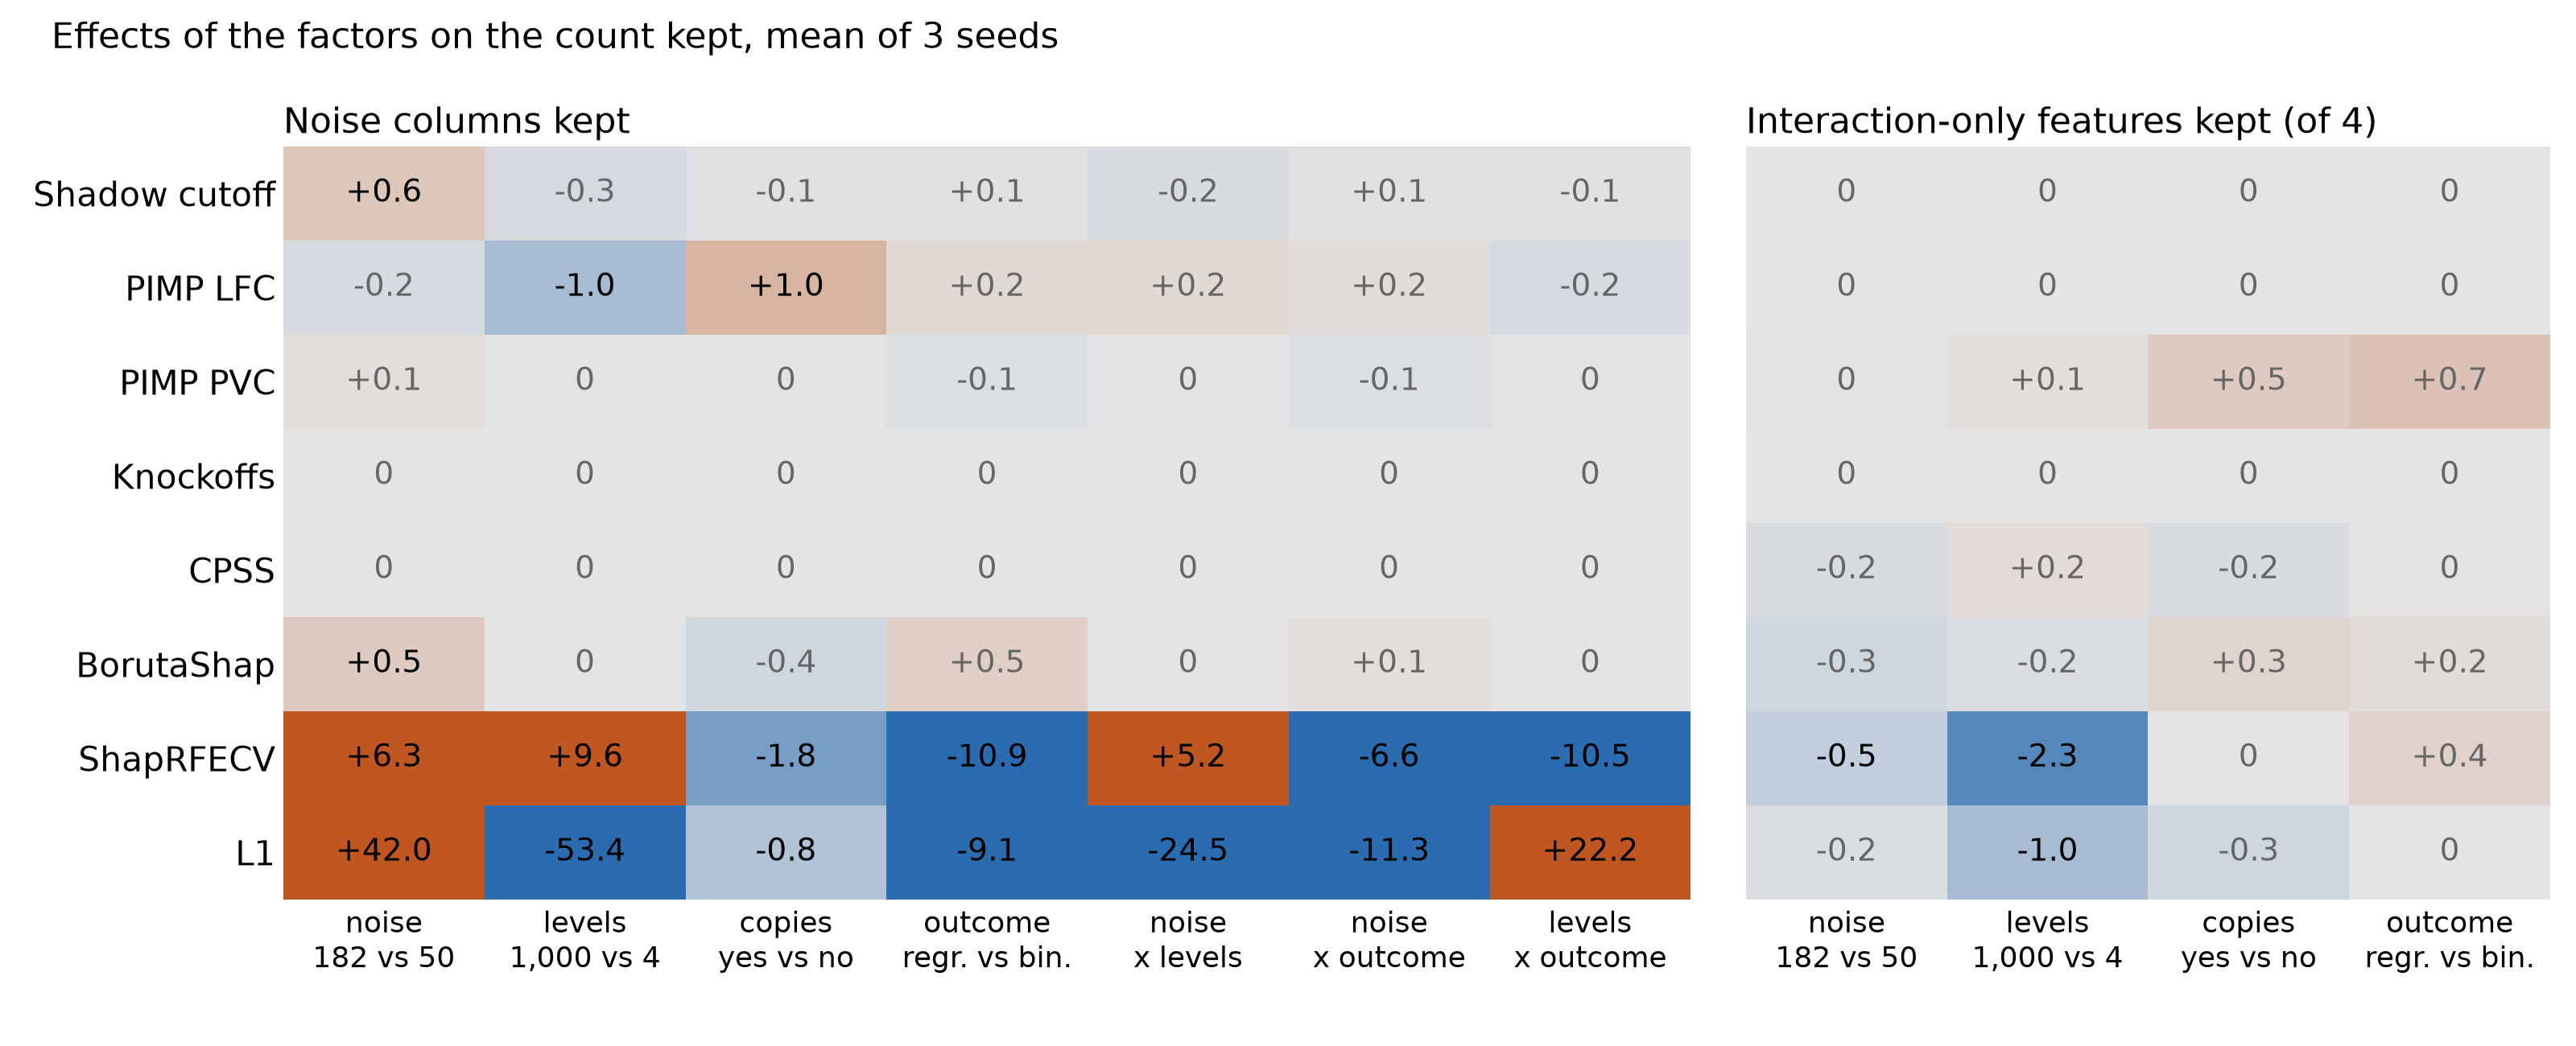

In [8]:
DIVERGING = LinearSegmentedColormap.from_list("diverging", ["#2b6cb0", "#e5e5e5", "#c05621"])
PANELS = [("noise_kept", "Noise columns kept",
           ["noise", "card", "copies", "outcome", "noise x card", "noise x outcome", "card x outcome"]),
          ("inter", "Interaction-only features kept (of 4)", list(FACTORS))]
LABELS = {"noise": "noise\n182 vs 50", "card": "levels\n1,000 vs 4", "copies": "copies\nyes vs no",
          "outcome": "outcome\nregr. vs bin.", "noise x card": "noise\nx levels", "noise x outcome": "noise\nx outcome",
          "card x outcome": "levels\nx outcome"}
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [7, 4]})
for ax, (resp, title, terms) in zip(axes, PANELS):
    e = effects(r8, resp, terms)
    ax.imshow([[e[(s, t)][0] for t in terms] for s in RULES], cmap=DIVERGING, vmin=-3, vmax=3, aspect="auto")
    for i, s in enumerate(RULES):
        for j, t in enumerate(terms):
            mean, seeds = e[(s, t)]
            firm = abs(mean) >= 0.5 and all(np.sign(x) == np.sign(mean) for x in seeds)
            ax.text(j, i, f"{mean:+.1f}" if abs(mean) >= 0.05 else "0", ha="center", va="center", fontsize=14,
                    color="black" if firm else "0.4")
    ax.set_xticks(range(len(terms)), [LABELS[t] for t in terms], fontsize=13)
    ax.set_yticks(range(len(RULES)), RULES if ax is axes[0] else [])
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
    ax.set_title(title, loc="left")
fig.suptitle("Effects of the factors on the count kept, mean of 3 seeds", x=0.02, ha="left", fontsize=16)
fig.subplots_adjust(left=0.11, right=0.99, top=0.86, bottom=0.14, wspace=0.05)
fig.savefig("selector_characterization_effects.png")
plt.show()

## 8b: relabeled category codes

The codes of city and of every categorical noise column are permuted, the same permutation in the
training rows and the fresh draw. No information changes. Cells: the base cell and the 1,000-level
cell (182 noise columns, binary outcome, no copies), seeds of 8a. The kept sets of every rule except
knockoffs and ShapRFECV (left out to save run time) are compared with 8a; for RF impurity the change is set against a refit with another random
state on the original codes.

A second check reads city in a code order that matters: on the pool at s = 1, city coded in the order
of its price level against `CITY_RELABEL`, the order least correlated with the price level.

In [9]:
def relabel_codes(frames, cats, seed):
    # one permutation of the codes per column, applied to every frame
    rng = np.random.default_rng((seed + AUX_OFFSET, 5))
    out = [f.copy() for f in frames]
    for c in cats:
        levels = np.unique(np.concatenate([f[c].to_numpy() for f in frames]))
        new = pd.Series(rng.permutation(levels), index=levels)
        for o, f in zip(out, frames):
            o[c] = new.loc[f[c]].to_numpy()
    return out


def jaccard(a, b):
    a, b = set(a), set(b)
    return len(a & b) / len(a | b) if a | b else 1.0


def run8b(card, seed):
    d = cell_data(seed, 182, card, False, "binary")
    df, fresh = relabel_codes([d.df, d.fresh], d.cats, seed)
    r = d._replace(df=df, fresh=fresh, Xtr=df.loc[d.Xtr.index], Xte=df.loc[d.Xte.index])
    rows, _ = run_rules(r, seed, with_shap=False)
    out = [dict(card=card, seed=seed, selector=x["selector"], kept=x["kept"]) for x in rows]
    lfc_d = lfc(d, fit_cb(d, d.Xtr, d.ytr), d.Xte, d.yte)
    lfc_r = lfc(r, fit_cb(r, r.Xtr, r.ytr), r.Xte, r.yte)
    top = lambda v: list(v.nlargest(TOP).index)
    rf_top = top(rf_impurity(d, seed))
    out += [dict(card=card, seed=seed, selector="CB LFC", max_diff=float((lfc_d - lfc_r).abs().max())),
            dict(card=card, seed=seed, selector="Pair scan", max_diff=float((pair_scan(d) - pair_scan(r)).abs().max())),
            dict(card=card, seed=seed, selector="RF impurity", jaccard_relabel=jaccard(rf_top, top(rf_impurity(r, seed))),
                 jaccard_reseed=jaccard(rf_top, top(rf_impurity(d, seed + 1))))]
    return out


def city_order(seed):
    # rank of city in RF impurity on the pool at s = 1: CITY_RELABEL codes, price-ordered codes, and a new random state
    df, y = gen_cell(seed, s=1.0)
    Xtr, _, ytr, _ = split(df, y, seed)
    ordered = Xtr.assign(city=np.argsort(CITY_RELABEL)[Xtr.city])     # code = price level index
    rank = lambda X, rs: int(rf_impurity(SimpleNamespace(Xtr=X, ytr=ytr, task="binary"), rs)
                             .rank(ascending=False, method="max")["city"])
    return dict(seed=seed, relabel=rank(Xtr, seed), price_order=rank(ordered, seed), reseed=rank(Xtr, seed + 1))


with timed("Part 8b"):
    R8B = pd.DataFrame([r for seed in SEEDS8 for card in CARD_LEVELS for r in cached(f"8b_{card}_{seed}", run8b, card, seed)])
    CITY8B = pd.DataFrame([cached(f"8b_city_{seed}", city_order, seed) for seed in SEEDS8])
ref = R8A[(R8A.noise == 182) & ~R8A.copies & (R8A.outcome == "binary")].set_index(["card", "seed", "selector"]).kept
K8B = R8B.dropna(subset=["kept"])
K8B = K8B.assign(same=K8B.apply(lambda r: set(r.kept) == set(ref[(r.card, r.seed, r.selector)]), axis=1))
print("Kept set identical after relabeling, per rule (cells x seeds):",
      K8B.groupby("selector").same.agg(lambda s: f"{s.sum()} of {len(s)}").to_dict())
print(R8B[R8B.selector.isin(["CB LFC", "Pair scan", "RF impurity"])].drop(columns="kept").dropna(axis=1, how="all").round(3).to_string(index=False))
print("\nRF impurity rank of city at s = 1 (of 196):")
print(CITY8B.set_index("seed").to_string())

  8b_4_7100: 682 s


  8b_1000_7100: 796 s


  8b_4_7101: 676 s


  8b_1000_7101: 788 s


  8b_4_7102: 685 s


  8b_1000_7102: 797 s


  8b_city_7100: 6 s


  8b_city_7101: 6 s


  8b_city_7102: 5 s


Kept set identical after relabeling, per rule (cells x seeds): {'BorutaShap': '6 of 6', 'CPSS': '6 of 6', 'L1': '6 of 6', 'PIMP LFC': '6 of 6', 'PIMP PVC': '6 of 6', 'Shadow cutoff': '6 of 6'}
 card  seed    selector  max_diff  jaccard_relabel  jaccard_reseed
    4  7100      CB LFC       0.0              NaN             NaN
    4  7100   Pair scan       0.0              NaN             NaN
    4  7100 RF impurity       NaN            0.750           0.750
 1000  7100      CB LFC       0.0              NaN             NaN
 1000  7100   Pair scan       0.0              NaN             NaN
 1000  7100 RF impurity       NaN            0.867           0.750
    4  7101      CB LFC       0.0              NaN             NaN
    4  7101   Pair scan       0.0              NaN             NaN
    4  7101 RF impurity       NaN            0.867           0.647
 1000  7101      CB LFC       0.0              NaN             NaN
 1000  7101   Pair scan       0.0              NaN             NaN
 10

## 8c: two public tables

- **Default of Credit Card Clients** (Yeh and Lien 2009; OpenML 42477, CC0): 30,000 clients, 23
  columns, default next month (22%). Sex, education and marriage are categorical; the six monthly bill
  amounts correlate 0.80 to 0.95 with each other.
- **Diabetes 130-US** (Strack et al. 2014; OpenML 46922, the TabArena version, CC BY 4.0): one stay per
  patient (71,518), here a random 30,000 per seed, readmission within 30 days (8.8%). The diagnosis
  codes diag_1 to diag_3 have 609 to 651 levels in the 30,000 rows; categorical columns are coded as integers in sorted
  order, missing values as their own level.

Per seed a random third of the rows is the fresh draw, and the rest is split 70/30 as in 8a.

- **Mode 1, real outcome:** the real columns plus the 182 noise columns of the pool (4 levels). There is
  no known truth for the real columns, so the responses are the noise kept and the refit gap to all
  real columns.
- **Mode 2, synthetic outcome:** the real columns plus u and v; the binary outcome is drawn from a
  logit with 6 fixed real columns (each mapped to normal scores by rank, coefficients 0.4, -0.4, ...),
  the XOR term of u and v of the pool at s = 0.25, and intercept -1. The useful features are the 6
  columns, u and v. Credit Card: bill_amt1 is in the logit and bill_amt2-6 are not, so they act as
  real-data copies. Diabetes: diag_1 to diag_3 are added a second time, shuffled within column, which
  keeps their levels and removes any link to the outcome.

Knockoffs are not run in 8c: an exact knockoff needs the distribution of the real columns.

In [10]:
N8C = 6_000 if QUICK else 30_000
CREDIT_NAMES = (["limit_bal", "sex", "education", "marriage", "age"] + [f"pay_{k}" for k in (0, 2, 3, 4, 5, 6)]
                + [f"bill_amt{k}" for k in range(1, 7)] + [f"pay_amt{k}" for k in range(1, 7)])
Y_COLS = {"credit": ["limit_bal", "age", "pay_0", "bill_amt1", "pay_amt1", "pay_amt3"],
          "diabetes": ["time_in_hospital", "num_lab_procedures", "num_medications", "number_inpatient",
                       "number_diagnoses", "age"]}
SHUFFLED = {"credit": [], "diabetes": ["diag_1", "diag_2", "diag_3"]}   # added a second time, shuffled within column


def load_table(name):
    # columns (categorical ones as integer codes in sorted order), outcome, categorical columns
    if name == "credit":
        d = fetch_openml(data_id=42477, as_frame=True, parser="auto").frame
        X = d[[f"x{i}" for i in range(1, 24)]].set_axis(CREDIT_NAMES, axis=1).astype(float)
        cats = ["sex", "education", "marriage"]
        return X.astype({c: int for c in cats}), (d["y"].astype(str) == "1").astype(int).to_numpy(), cats
    d = fetch_openml(data_id=46922, as_frame=True, parser="auto").frame
    y = (d.pop("EarlyReadmission").astype(str) == "Yes").astype(int).to_numpy()
    d["age"] = d["age"].astype(str).str.extract(r"\[(\d+)-", expand=False).astype(int) + 5   # age bracket midpoint
    cats = [c for c in d if not pd.api.types.is_numeric_dtype(d[c])]
    d[cats] = OrdinalEncoder(dtype=np.int64).fit_transform(d[cats].astype(object).fillna("missing").astype(str))
    return d, y, cats


TABLES = {name: load_table(name) for name in ("credit", "diabetes")}
for name, (X, y, cats) in TABLES.items():
    print(f"{name}: {X.shape[0]:,} rows, {X.shape[1]} columns ({len(cats)} categorical), base rate {y.mean():.3f}")


def table_data(name, mode, seed):
    X, y, cats = TABLES[name]
    rng = np.random.default_rng((seed, 8))
    rows = rng.choice(len(X), min(N8C, len(X)), replace=False)
    X, y = X.iloc[rows].reset_index(drop=True), y[rows]
    n = len(X)
    if mode == "real":
        noise = gen_cell(seed, n=n)[0].filter(like="noise")      # the 182 noise columns of the pool
        X, useful, inter, noise_cols = pd.concat([X, noise], axis=1), [], [], list(noise.columns)
        cats = cats + [c for c in noise if c.startswith("cnoise")]
    else:
        u, v = rng.normal(size=n), rng.normal(size=n)
        normal_scores = lambda c: stats.norm.ppf((X[c].rank(method="average") - 0.5) / n)
        logit = (sum(a * normal_scores(c) for a, c in zip(ADD_COEF, Y_COLS[name]))
                 + 1.5 * S8 * np.sign(u) * np.sign(v) + POOL_INTERCEPT)
        y = rng.binomial(1, 1 / (1 + np.exp(-logit)))
        X = X.assign(u=u, v=v, **{f"{c}_shuffled": rng.permutation(X[c].to_numpy()) for c in SHUFFLED[name]})
        cats = cats + [f"{c}_shuffled" for c in SHUFFLED[name]]
        useful, inter, noise_cols = Y_COLS[name] + ["u", "v"], ["u", "v"], []
    sel, fresh = train_test_split(np.arange(n), test_size=1 / 3, random_state=seed, stratify=y)
    df = X.iloc[sel].reset_index(drop=True)
    return Data(df, y[sel], *split(df, y[sel], seed), X.iloc[fresh].reset_index(drop=True), y[fresh], "binary",
                cats, noise_cols, useful, inter, [], 4)


def run8c(name, mode, seed):
    d = table_data(name, mode, seed)
    # with the real outcome there are no known true features: the gap is to the refit on all real columns
    rules, base = run_rules(d, seed, ref=[c for c in d.df if c not in d.noise] if mode == "real" else None)
    for r in rules:
        r["real_kept"] = len(set(r["kept"]) - set(d.noise))
    return [dict(table=name, mode=mode, seed=seed, base=base, **r) for r in rules + run_scores(d, seed)]


with timed("Part 8c"):
    R8C = pd.DataFrame([r for name in TABLES for mode in ("real", "synthetic") for seed in SEEDS8
                        for r in cached(f"8c_{name}_{mode}_{seed}", run8c, name, mode, seed)])
for (name, mode), g in R8C[R8C.selector.isin(RULES)].groupby(["table", "mode"], sort=False):
    cols = ["real_kept", "noise_kept", "gap"] if mode == "real" else ["useful", "inter", "gap"]
    print(f"\n{name}, {mode} outcome: per seed")
    print(g.assign(**{c: g[c].round(3) for c in cols}).pivot(index="selector", columns="seed", values=cols).to_string())

credit: 30,000 rows, 23 columns (3 categorical), base rate 0.221
diabetes: 71,518 rows, 47 columns (38 categorical), base rate 0.088


  8c_credit_real_7100: 1066 s


  8c_credit_real_7101: 1217 s


  8c_credit_real_7102: 1269 s


  8c_credit_synthetic_7100: 450 s


  8c_credit_synthetic_7101: 443 s


... (4 outputs left out)

  8c_diabetes_synthetic_7100: 1010 s


  8c_diabetes_synthetic_7101: 1049 s


  8c_diabetes_synthetic_7102: 937 s



credit, real outcome: per seed
              real_kept             noise_kept                 gap              
seed               7100  7101  7102       7100   7101  7102   7100   7101   7102
selector                                                                        
BorutaShap         14.0  13.0  13.0        0.0    0.0   0.0  0.001 -0.002  0.001
CPSS                9.0   8.0  10.0        0.0    0.0   0.0 -0.001 -0.012 -0.003
L1                 18.0  18.0  10.0      125.0  116.0   4.0 -0.005 -0.012 -0.001
PIMP LFC           14.0  11.0  15.0        2.0    2.0   3.0  0.004 -0.003  0.004
PIMP PVC           14.0  16.0  17.0        1.0    3.0   6.0  0.004  0.002  0.003
Shadow cutoff      12.0  12.0  13.0        1.0    0.8   0.0  0.001 -0.005  0.001
ShapRFECV          16.0   9.0  15.0       39.0    4.0  29.0 -0.005 -0.016 -0.018

credit, synthetic outcome: per seed
              useful           inter              gap              
seed            7100 7101 7102  7100 7101 7102   7100

## Hypotheses

A main effect is the mean of the 24 matched differences. "Confirmed" needs every clause to hold in the
mean and in all 3 seeds, "partly" at least one clause in the mean and in 2 of 3 seeds, otherwise "not
confirmed".

- **H36 (levels).** In RF impurity, moving the categorical noise columns from 4 to 1,000 levels lifts
  them from the bottom of the noise ranking to its middle: their median scaled rank among the noise
  columns is at least 0.9 in every 4-level run and between 0.3 and 0.7 in every 1,000-level run. The
  number of noise columns in the RF top 14 changes by less than 1 on average. For shadow cutoff, PIMP
  LFC, PIMP PVC, BorutaShap, knockoffs and CPSS the absolute main effect on noise kept is below 0.5,
  and each keeps at least 12 of the 14 useful features on average at both levels: each compares a
  column with a null of the same number of levels.
- **H37 (copies, group knockoffs).** Group knockoffs keep either 0 or all 5 copies of a block, and all
  10 copies in at least 20 of the 24 copy runs: a group test cannot tell a copy from its original. The
  shadow cutoff and PIMP LFC keep fewer copies than group knockoffs in at least 20 of the 24 copy runs,
  and at most 2 copies per run on average: LFC credits a copy only with the share of the model's
  splits it carries.
- **H38 (outcome).** The binary outcome is the sign of the regression outcome, so it carries less
  information. For shadow cutoff, PIMP LFC, knockoffs and CPSS (4 of 4 in the binary base cell) the
  main effect of regression on interaction-only features kept is at least -0.25; for PIMP PVC and
  BorutaShap it is at least +0.5. The CPSS selection frequency of city is higher with the regression
  outcome in all 3 seeds. L1 and ShapRFECV are reported without a verdict: their CV metric changes
  with the outcome.
- **H39 (noise columns).** The absolute main effect of the number of noise columns (182 against 50) on
  noise kept is below 0.5 for knockoffs, CPSS, PIMP LFC and PIMP PVC, and each keeps at least 12 of the
  14 useful features on average at both levels. For the shadow cutoff the effect is within 0.5 of the
  exchangeability prediction 182/197 - 50/65 = 0.15. For ShapRFECV it is at least 2. BorutaShap's
  spread between seeds is reported next to the shadow cutoff's, without a verdict.
- **H40 (relabeling).** Relabeling the category codes leaves the CB LFC scores, the kept sets of the
  shadow cutoff, PIMP, CPSS and BorutaShap, and the pair-scan scores identical in all 3 seeds (scores up
  to 1e-9, the rounding of a sum taken in another order); L1 (with
  a fixed random state) keeps the same set. For RF impurity the top-14 Jaccard index between the
  original and the relabeled codes is at least that between two random states on the original codes,
  in at least 2 of 3 seeds. On the pool at s = 1, coding city in the order of its price level moves
  city at least 20 places up the RF impurity ranking in all 3 seeds, more than a new random state
  moves it.
- **H41 (real tables, synthetic outcome).** Credit Card: for each of shadow cutoff, PIMP LFC and CPSS,
  keeping at least one of bill_amt2-6 in at least 2 of 3 seeds matches keeping at least one copy in
  more than half of the 24 copy runs of 8a. Diabetes: each shuffled diag column ranks above every
  numeric column outside the synthetic logit in RF impurity in all 3 seeds, and shadow cutoff, PIMP LFC
  and CPSS keep none of them.
- **H42 (copies take places).** Copies lower the CPSS selection frequency of city in all 3 seeds and the
  number of interaction-only features in the pair-scan top 14 (main effect at most -1). For shadow
  cutoff, PIMP LFC and CPSS the main effect of copies on the number of distance_km and u kept is at
  most -0.5. Group knockoffs keep both in at least 22 of the 24 copy runs.
- **H43 (error control).** Over all 48 runs the mean false discovery proportion of knockoffs at group
  level (noise groups kept divided by groups kept) is at most 0.1. CPSS keeps on average no more noise
  than its bound 14^2 / (0.5 p) in each of the 16 cells (2.0 at 196 columns, 6.1 at 64).
- **H44 (L1 and levels).** At 182 noise columns, L1 keeps at least 3 more categorical noise columns
  with a nonzero coefficient at 1,000 levels than at 4 levels (mean over the 12 matched pairs), and the
  interaction of levels and noise columns on noise kept is at least 1.
- **H45 (noise columns and PIMP PVC).** PIMP PVC keeps more interaction-only features at 182 noise
  columns than at 50: the main effect is at least +0.5. For PIMP LFC it is below 0.5 in absolute value.
  PVC sums to 100 in every fit, so the null bar of a column is about 100/p and rises when noise is
  removed.
- **H46 (knockoffs per column).** With knockoffs per column for the copy blocks, knockoffs keep at most
  1 copy per run on average over the 24 copy runs, and lose distance_km or u in at least half of them.

In [11]:
def eff(response, sel, term):
    return effects(R8A[R8A.selector == sel], response, [term])[(sel, term)]


def all_seeds(e, test):
    # (mean passes, number of seeds that pass)
    return test(e[0]), sum(test(x) for x in e[1])


def ok(cond):
    # a clause tested on all runs at once: it passes or fails in every seed together
    return bool(cond), len(SEEDS8)


def eff_checks(response, sels, term, test):
    return [all_seeds(eff(response, s, term), test) for s in sels]


def eff_line(response, sels, term):
    return ", ".join(f"{s} {eff(response, s, term)[0]:+.2f}" for s in sels)


def grade(results):
    # results: list of (mean ok, seeds ok); confirmed if every clause passes in the mean and in all seeds
    n = len(SEEDS8)
    if all(m and s == n for m, s in results):
        return "confirmed"
    return "partly" if any(m and s >= min(2, n) for m, s in results) else "not confirmed"


def per_run(sel, copies=False):
    g = R8A[R8A.selector == sel]
    return g[g.copies] if copies else g


LFC3 = ["Shadow cutoff", "PIMP LFC", "CPSS"]
H, EV = {}, {}

S36 = ["Shadow cutoff", "PIMP LFC", "PIMP PVC", "BorutaShap", "Knockoffs", "CPSS"]
rf = per_run("RF impurity")
r4, r1k = rf[rf.card == 4].cat_noise_rank, rf[rf.card == 1000].cat_noise_rank
c36 = [ok((r4 >= 0.9).all()), ok(r1k.between(0.3, 0.7).all()),
       all_seeds(eff("noise_kept", "RF impurity", "card"), lambda x: abs(x) < 1)]
c36 += eff_checks("noise_kept", S36, "card", lambda x: abs(x) < 0.5)
c36 += [ok(per_run(s).groupby("card").useful.mean().min() >= 12) for s in S36]
H["H36"] = grade(c36)
EV["H36"] = (f"RF cat-noise rank at 4 levels {r4.min():.2f} to {r4.max():.2f}, at 1000 {r1k.min():.2f} to {r1k.max():.2f}; "
             f"RF top-14 noise effect {eff('noise_kept', 'RF impurity', 'card')[0]:+.2f}; noise effect "
             + eff_line("noise_kept", S36, "card"))

ko = per_run("Knockoffs", copies=True)
run_key = ["noise", "card", "outcome", "seed"]
c37 = [ok(ko.copies_kept.isin([0, 5, 10]).all() and (ko.copies_kept == 10).sum() >= 20)]
for sel in ["Shadow cutoff", "PIMP LFC"]:
    g = per_run(sel, copies=True).set_index(run_key).copies_kept
    c37.append(ok((g < ko.set_index(run_key).copies_kept).sum() >= 20 and g.mean() <= 2))
H["H37"] = grade(c37)
EV["H37"] = (f"group knockoffs copies per run {sorted(ko.copies_kept.unique().tolist())}, all 10 in {(ko.copies_kept == 10).sum()} of {len(ko)}; "
             + "; ".join(f"{s} mean copies {per_run(s, copies=True).copies_kept.mean():.2f}" for s in ["Shadow cutoff", "PIMP LFC"]))

S38 = ["Shadow cutoff", "PIMP LFC", "Knockoffs", "CPSS"]
c38 = (eff_checks("inter", S38, "outcome", lambda x: x >= -0.25)
       + eff_checks("inter", ["PIMP PVC", "BorutaShap"], "outcome", lambda x: x >= 0.5)
       + [all_seeds(eff("freq_city", "CPSS", "outcome"), lambda x: x > 0)])
H["H38"] = grade(c38)
EV["H38"] = (eff_line("inter", S38 + ["PIMP PVC", "BorutaShap", "L1", "ShapRFECV"], "outcome")
             + f"; CPSS city frequency {eff('freq_city', 'CPSS', 'outcome')[0]:+.3f}")

S39 = ["Knockoffs", "CPSS", "PIMP LFC", "PIMP PVC"]
c39 = (eff_checks("noise_kept", S39, "noise", lambda x: abs(x) < 0.5)
       + [ok(per_run(s).groupby("noise").useful.mean().min() >= 12) for s in S39]
       + [all_seeds(eff("noise_kept", "Shadow cutoff", "noise"), lambda x: abs(x - (182 / 197 - 50 / 65)) <= 0.5),
          all_seeds(eff("noise_kept", "ShapRFECV", "noise"), lambda x: x >= 2)])
H["H39"] = grade(c39)
spread = {s: per_run(s).groupby(list(FACTORS)).noise_kept.std().mean() for s in ["BorutaShap", "Shadow cutoff"]}
EV["H39"] = (eff_line("noise_kept", S39 + ["Shadow cutoff", "ShapRFECV"], "noise")
             + "; SD of noise kept between seeds, mean over cells: " + ", ".join(f"{k} {v:.2f}" for k, v in spread.items()))

same_ok = bool(K8B[K8B.selector.isin(["Shadow cutoff", "PIMP LFC", "PIMP PVC", "CPSS", "BorutaShap", "L1"])].same.all())
num = R8B[R8B.selector.isin(["CB LFC", "Pair scan"])]
rfb = R8B[R8B.selector == "RF impurity"]
rf_seeds = rfb.groupby("seed").apply(lambda g: (g.jaccard_relabel >= g.jaccard_reseed).all()).sum()
city_up = CITY8B.relabel - CITY8B.price_order
c40 = [ok(same_ok and (num.max_diff <= 1e-9).all()),   # 1e-9: summation order of the pair scan
       ok(rf_seeds >= min(2, len(SEEDS8))),             # the clause itself is "in at least 2 of 3 seeds"
       ok(((city_up >= 20) & (city_up > (CITY8B.relabel - CITY8B.reseed).abs())).all())]
H["H40"] = grade(c40)
EV["H40"] = (f"kept sets identical: {same_ok}; largest score difference CB LFC {num[num.selector == 'CB LFC'].max_diff.max():.2g}, "
             f"pair scan {num[num.selector == 'Pair scan'].max_diff.max():.2g}; RF Jaccard relabel {rfb.jaccard_relabel.round(2).tolist()} "
             f"against reseed {rfb.jaccard_reseed.round(2).tolist()}; city rank up by price order {city_up.tolist()}")

cc = R8C[(R8C.table == "credit") & (R8C["mode"] == "synthetic")]
dd = R8C[(R8C.table == "diabetes") & (R8C["mode"] == "synthetic")]
bill = lambda k: any(f"bill_amt{j}" in k for j in range(2, 7))
copy8a = {s: (per_run(s, copies=True).copies_kept >= 1).mean() for s in LFC3}
c41 = [ok((cc[cc.selector == s].kept.apply(bill).sum() >= 2) == (copy8a[s] > 0.5)) for s in LFC3]
rk = dd[dd.selector == "RF impurity"]
shuffled = [f"{c}_shuffled" for c in SHUFFLED["diabetes"]]
X_d, _, cats_d = TABLES["diabetes"]
non_signal = [c for c in X_d if c not in cats_d and c not in Y_COLS["diabetes"]]
best_other = rk.ranks.apply(lambda r: min(r[n] for n in non_signal))
above = rk.ranks.apply(lambda r: max(r[c] for c in shuffled)) < best_other
c41.append((bool(above.all()), int(above.sum())))
c41.append(ok(all(dd[dd.selector == s].kept.apply(lambda k: not set(k) & set(shuffled)).all() for s in LFC3)))
H["H41"] = grade(c41)
EV["H41"] = ("Credit Card, seeds keeping one of bill_amt2-6: "
             + ", ".join(f"{s} {cc[cc.selector == s].kept.apply(bill).sum()}" for s in LFC3)
             + "; share of 8a copy runs with a copy kept: " + ", ".join(f"{s} {v:.2f}" for s, v in copy8a.items())
             + f"; Diabetes: RF ranks of the shuffled diag columns {rk.ranks.apply(lambda r: [r[c] for c in shuffled]).tolist()}, "
             f"best non-signal numeric column {best_other.tolist()}")

both = (ko.dist_u == 2).sum()
c42 = [all_seeds(eff("freq_city", "CPSS", "copies"), lambda x: x < 0),
       all_seeds(eff("inter", "Pair scan", "copies"), lambda x: x <= -1)]
c42 += eff_checks("dist_u", LFC3, "copies", lambda x: x <= -0.5)
c42.append(ok(both >= 22))
H["H42"] = grade(c42)
EV["H42"] = (f"CPSS city frequency {eff('freq_city', 'CPSS', 'copies')[0]:+.3f}; pair scan interaction-only in top 14 "
             f"{eff('inter', 'Pair scan', 'copies')[0]:+.2f}; distance_km and u kept " + eff_line("dist_u", LFC3, "copies")
             + f"; group knockoffs keep both in {both} of {len(ko)} copy runs")

kall = per_run("Knockoffs")
fdp = (kall.noise_groups_kept / kall.groups_kept.where(kall.groups_kept > 0)).fillna(0)
cell = per_run("CPSS").groupby(list(FACTORS)).agg(noise=("noise_kept", "mean"), copies=("copies_kept", "mean"), p=("p", "first"))
cell["bound"] = CPSS_TOP ** 2 / ((2 * CPSS_PI - 1) * cell.p)
c43 = [ok(fdp.mean() <= 0.1), ok((cell.noise <= cell.bound).all())]
H["H43"] = grade(c43)
EV["H43"] = (f"knockoffs mean FDP {fdp.mean():.3f} (largest run {fdp.max():.2f}); CPSS cells with mean noise above the bound: "
             f"{(cell.noise > cell.bound).sum()} of {len(cell)}, counting copies as false selections: "
             f"{(cell.noise + cell.copies > cell.bound).sum()}")

l1r = per_run("L1")
pairs44 = l1r[l1r.noise == 182].pivot_table(index=["copies", "outcome", "seed"], columns="card", values="cat_noise_nonzero")
d44 = pairs44[1000] - pairs44[4]
c44 = [(bool(d44.mean() >= 3), int((d44.groupby(level="seed").mean() >= 3).sum())),
       all_seeds(eff("noise_kept", "L1", "noise x card"), lambda x: x >= 1)]
H["H44"] = grade(c44)
EV["H44"] = (f"categorical noise columns nonzero, 1000 minus 4 levels at 182 noise columns: {d44.mean():+.2f}; "
             f"interaction on noise kept {eff('noise_kept', 'L1', 'noise x card')[0]:+.2f}")

c45 = [all_seeds(eff("inter", "PIMP PVC", "noise"), lambda x: x >= 0.5),
       all_seeds(eff("inter", "PIMP LFC", "noise"), lambda x: abs(x) < 0.5)]
H["H45"] = grade(c45)
EV["H45"] = "main effect on interaction-only kept: " + eff_line("inter", ["PIMP PVC", "PIMP LFC"], "noise")

kc = per_run("Knockoffs (column)")
c46 = [ok(kc.copies_kept.mean() <= 1), ok((kc.dist_u < 2).sum() >= len(kc) / 2)]
H["H46"] = grade(c46)
EV["H46"] = f"copies kept per run {kc.copies_kept.mean():.2f}; runs losing distance_km or u: {(kc.dist_u < 2).sum()} of {len(kc)}"

with pd.option_context("display.max_colwidth", 400):
    print(pd.DataFrame({"verdict": H, "evidence": EV}).to_string())

           verdict                                                                                                                                                                                                                                                                                                          evidence
H36         partly                                                                                                   RF cat-noise rank at 4 levels 0.91 to 0.92, at 1000 0.39 to 0.88; RF top-14 noise effect +0.04; noise effect Shadow cutoff -0.28, PIMP LFC -1.00, PIMP PVC -0.04, BorutaShap -0.04, Knockoffs +0.00, CPSS +0.00
H37         partly                                                                                                                                                                                              group knockoffs copies per run [10.0], all 10 in 24 of 24; Shadow cutoff mean copies 5.36; PIMP LFC mean copies 5.46
H38         partly       

## Summary

**8a, where each rule breaks (Figure 1).**

- **Knockoffs and CPSS** keep no noise column in any of the 48 runs, so H43 holds. Knockoffs keep all
  14 useful features in every run; CPSS loses one in 7 of the 24 copy runs (city in 5, distance_km in
  2) and in no other run. On the copies, group knockoffs keep all 10 in every copy run (H37), CPSS and
  knockoffs per column none (H46).
- **Shadow cutoff and PIMP LFC** keep about one noise column per run (0.9 and 1.1). In all 3 seeds PIMP
  LFC keeps one fewer at 1,000 levels and one more with copies, and the shadow cutoff 0.6 more at 182
  noise columns. Both keep 3 to 5 of the 5 copies of distance_km in every copy run, and copies of u in
  6 (shadow cutoff) and 13 (PIMP LFC) of the 24 runs: they test a column against noise, not against its
  original, so nothing in them rejects a copy the model uses. The originals stay (distance_km and u kept
  move by less than 0.1), while the pair scan gives 4.4 places of its top 14 to copies and keeps 1.3 of
  the 4 interaction-only features instead of 4 (H42).
- **ShapRFECV** breaks at 1,000 levels. With the binary outcome it keeps every categorical noise column
  in every run (9 of 9 at 50 noise columns, 32 of 32 at 182) and still drops u and v in all 12 runs,
  city too at 182 noise columns. With the regression outcome it keeps almost no noise but drops hour, u
  and v in all 12 runs. Its model is LightGBM, so the run cannot separate the selector from the model.
- **L1** keeps far fewer noise columns at 1,000 levels with both outcomes (131 against 14 of 182 with
  the binary outcome, 71 against 33 with the regression one), but its categorical noise columns move in
  opposite directions: 18.7 fewer of the 32 with the binary outcome, 10.0 more with the regression one.
  The pooled -4.3 of H44 hides both, and since the two outcomes tune the penalty differently (see the
  selectors), the run cannot attribute the difference to the outcome alone. A linear model has no term
  for hour, u and v, which act only through interactions: at 4 levels L1 keeps hour in 4 of 24 runs
  and u and v about as often as a Gaussian noise column, at 1,000 levels none of them.
- **BorutaShap** keeps about half a noise column more at 182 noise columns, in all 3 seeds, and varies
  more between seeds than the shadow cutoff (SD 0.53 against 0.39).
- **The refit** on the kept columns hides most of this (no main effect on the ROC AUC gap above 0.013).
  The largest losses come where ShapRFECV drops interaction-only features at
  1,000 levels: 0.03 ROC AUC with the binary outcome at 182 noise columns, 0.06 R2 with the regression
  outcome. L1 sits 0.02 to 0.04 ROC AUC and 0.04 to 0.07 R2 below the refit on the useful features in
  every cell, 0.024 with 2.3 noise columns kept and 0.036 with 131, so most of its gap likely comes
  from the useful features it drops.

**8b, relabeling (H40).** The kept sets of the six rules compared (all but knockoffs and ShapRFECV, in
the base cell and the 1,000-level cell) are identical after relabeling, and the CB LFC and pair-scan
scores differ by at most 2e-13. The RF impurity top 14 changes no more than with another random state.
Coding city in the order of its price level lifts it from rank 164 to 12-14 of 196 in RF impurity at
s = 1.

**8c, two public tables (H41).**

- Credit Card, synthetic outcome: CPSS keeps none of bill_amt2-6, as in 8a, but drops u in 2 of 3
  seeds and in those loses 0.02 to 0.03 ROC AUC. The shadow cutoff keeps one of the five in 2 of 3
  seeds and PIMP LFC in 1, against 3 to 5 of 5 copies in every 8a copy run, so the H41 match holds for
  the shadow cutoff and CPSS, not for PIMP LFC; 3 seeds cannot separate 2 of 3 from 1 of 3. PIMP PVC
  keeps only 3 or 4 of the 8 true features and loses 0.04 to 0.10 ROC AUC.
- Diabetes, synthetic outcome: RF impurity ranks the shuffled diag columns (over 500 levels in the
  training rows, no signal) 9th to 13th, above every numeric column outside the synthetic logit (14th
  or 15th at best) and above number_inpatient, which is in the logit (16th or 17th). ShapRFECV keeps all
  three in every seed, as in 8a, and the three original diag columns, also without signal here. L1
  keeps one or two in 2 of 3 seeds and drops both interaction-only features in all 3; no other rule
  keeps a shuffled column.
- Real outcomes: ShapRFECV keeps injected noise in every run (4 to 39 columns on Credit Card, 22 to 26
  on Diabetes), L1 more than 100 in three of six runs (125, 116, 115) and 0 to 4 in the others, PIMP
  LFC 2 to 7 and PIMP PVC 1 to 6, CPSS none. On Diabetes every rule's refit stays below the refit on all
  47 real columns in every seed, by 0.02 to 0.03 ROC AUC for CPSS and 0.05 to 0.07 for ShapRFECV.

"Partly": at least one clause holds in the mean and in 2 of 3 seeds, but not every clause in all 3.

| Hypothesis | Verdict | What failed |
|---|---|---|
| H36 | partly | the RF rank of 1,000-level noise is outside 0.3-0.7 in 3 of 24 runs (up to 0.88); PIMP LFC keeps 1.0 fewer noise columns at 1,000 levels. The shadow cutoff and CPSS show no level effect, though the stated reason (a null with the same number of levels) does not apply to them |
| H37 | partly | the shadow cutoff and PIMP LFC keep 5.4 and 5.5 copies per run, not at most 2 |
| H38 | partly | PIMP PVC +0.71 in the mean but 0 in one seed; BorutaShap +0.17, below 0.5 |
| H39 | partly | every clause holds in the mean, the shadow cutoff by 0.01 against the stated 0.15 (0.04 against 0.18 with the copy cells); PIMP LFC and the shadow cutoff each fail in one seed |
| H40 | confirmed | |
| H41 | partly | PIMP LFC keeps one of bill_amt2-6 in 1 seed, though it kept copies in all 8a runs |
| H42 | partly | copies do not lower the number of distance_km and u kept (+0.01, 0.00 and -0.08, not -0.5 or less) |
| H43 | confirmed | |
| H44 | not confirmed | L1 keeps 4.3 fewer categorical noise columns at 1,000 levels, not 3 more; the noise x levels interaction is -24.5, not at least +1 |
| H45 | partly | the PIMP PVC effect is -0.04, not +0.5 (only the PIMP LFC clause holds) |
| H46 | partly | knockoffs per column lose distance_km in 5 of 24 copy runs (all 5 with the binary outcome), not in half |

Limits: 3 seeds per cell, so an effect counts only if it is at least half a column with one sign in all
seeds; one interaction strength, s = 0.25; the 8a knockoffs draw from the known distribution of each
cell, a best case, and are not run on the real tables; CPSS takes the top 14, the true number of useful
features in 8a (8 in the 8c synthetic outcome); the 1,000 levels are equally likely, while real
categories are skewed (only the shuffled diag columns probe that).